# 01 — Exploratory Data Analysis

This notebook inspects the AI4I 2020 predictive-maintenance dataset before modeling. It is synthetic data; patterns found here are not evidence of performance on real equipment. Run from the repository root, or open the notebook in VS Code/Jupyter with the project root as the working directory. Figures are saved under `artifacts/eda/`.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

working_dir = Path.cwd().resolve()
project_root = next(
    (parent for parent in (working_dir, *working_dir.parents)
     if (parent / "src" / "data_loader.py").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Could not locate project root containing src/data_loader.py")
sys.path.insert(0, str(project_root))

from src.data_loader import load_dataset

sns.set_theme(style="whitegrid", context="notebook")
FIGURE_DIR = project_root / "artifacts" / "eda"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
df = load_dataset()
print(f"Loaded {len(df):,} records and {len(df.columns)} columns from {project_root}")

Loaded 10,000 records and 14 columns from C:\Users\TanishTushid\OneDrive\Desktop\Predictive Maintenance & Failure Prediction


## Dataset shape, schema, and integrity

The loader validates required columns, numeric columns, target values, and known machine types. This cell reports the actual data types, missing values, duplicates, and descriptive statistics; it does not impute or otherwise alter the observations.

In [2]:
print("Shape:", df.shape)
display(df.dtypes.rename("dtype").to_frame())
display(df.isna().sum().rename("missing_count").to_frame())
print("Exact duplicate rows:", int(df.duplicated().sum()))
display(df.describe(include="all").T)

Shape: (10000, 14)


,dtype
UDI,int64
Product ID,str
Type,str
Air temperature [K],float64
Process temperature [K],float64
Rotational speed [rpm],int64
Torque [Nm],float64
Tool wear [min],int64
Machine failure,int64
TWF,int64


,missing_count
UDI,0
Product ID,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Machine failure,0
TWF,0


Exact duplicate rows: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
UDI,10000.0,NaN,NaN,NaN,5000.5,2886.89568,1.0,2500.75,5000.5,7500.25,10000.0
Product ID,10000,10000,M14860,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Type,10000,3,L,6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Air temperature [K],10000.0,NaN,NaN,NaN,300.00493,2.000259,295.3,298.3,300.1,301.5,304.5
Process temperature [K],10000.0,NaN,NaN,NaN,310.00556,1.483734,305.7,308.8,310.1,311.1,313.8
Rotational speed [rpm],10000.0,NaN,NaN,NaN,1538.7761,179.284096,1168.0,1423.0,1503.0,1612.0,2886.0
Torque [Nm],10000.0,NaN,NaN,NaN,39.98691,9.968934,3.8,33.2,40.1,46.8,76.6
Tool wear [min],10000.0,NaN,NaN,NaN,107.951,63.654147,0.0,53.0,108.0,162.0,253.0
Machine failure,10000.0,NaN,NaN,NaN,0.0339,0.180981,0.0,0.0,0.0,0.0,1.0
TWF,10000.0,NaN,NaN,NaN,0.0046,0.067671,0.0,0.0,0.0,0.0,1.0


## Target distribution and imbalance

Failure is a minority class in this dataset. The printed counts and percentages quantify the imbalance; later model selection must use failure-sensitive metrics (especially recall, precision, and average precision), not accuracy alone.

,count,percent
Machine failure,,
0,9661,96.61
1,339,3.39


Observed failure prevalence: 3.39%
Non-failures per failure: 28.5:1


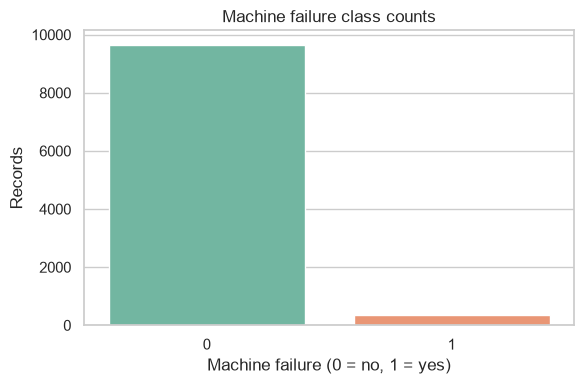

In [3]:
TARGET = "Machine failure"
target_counts = df[TARGET].value_counts().reindex([0, 1], fill_value=0)
target_percent = df[TARGET].value_counts(normalize=True).reindex([0, 1], fill_value=0) * 100
target_summary = pd.DataFrame({"count": target_counts, "percent": target_percent.round(2)})
display(target_summary.rename_axis("Machine failure"))
failure_rate = float(df[TARGET].mean())
imbalance_ratio = float(target_counts.loc[0] / target_counts.loc[1]) if target_counts.loc[1] else np.inf
print(f"Observed failure prevalence: {failure_rate:.2%}")
print(f"Non-failures per failure: {imbalance_ratio:.1f}:1")

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x=TARGET, hue=TARGET, legend=False, ax=ax, palette="Set2")
ax.set(title="Machine failure class counts", xlabel="Machine failure (0 = no, 1 = yes)", ylabel="Records")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "target_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

**Interpretation.** Use the exact prevalence and count ratio printed above to judge the class imbalance. A classifier that always predicts the majority class can appear accurate while detecting no failures, which is why later evaluation will include precision, recall, F1, PR-AUC, and false-negative counts.

## Feature eligibility and data-quality checks

The following columns are explicitly not model inputs:

- `Machine failure`: the outcome being predicted.
- `UDI` and `Product ID`: row/product identifiers, not generalizable sensor measurements.
- `TWF`, `HDF`, `PWF`, `OSF`, and `RNF`: failure-mode indicators that disclose failure-related information and would leak the target.

Eligible predictors for later work are machine `Type` and the measured air temperature, process temperature, rotational speed, torque, and tool wear. The checks below report observed categories and simple physical-domain violations; these are screening checks, not universal equipment limits.

In [4]:
EXCLUDED_COLUMNS = ["UDI", "Product ID", TARGET, "TWF", "HDF", "PWF", "OSF", "RNF"]
FEATURE_COLUMNS = [
    "Type", "Air temperature [K]", "Process temperature [K]",
    "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]",
]
print("Excluded columns:", EXCLUDED_COLUMNS)
print("Candidate feature columns:", FEATURE_COLUMNS)
print("Observed Type categories:", sorted(df["Type"].dropna().astype(str).unique()))

physical_checks = {
    "air temperature <= 0 K": df["Air temperature [K]"] <= 0,
    "process temperature <= 0 K": df["Process temperature [K]"] <= 0,
    "process temperature below air temperature": df["Process temperature [K]"] < df["Air temperature [K]"],
    "rotational speed <= 0 rpm": df["Rotational speed [rpm]"] <= 0,
    "negative torque": df["Torque [Nm]"] < 0,
    "negative tool wear": df["Tool wear [min]"] < 0,
}
display(pd.Series({name: int(mask.sum()) for name, mask in physical_checks.items()}, name="violations").to_frame())
print("UDI unique:", bool(df["UDI"].is_unique), "| Product ID unique:", bool(df["Product ID"].is_unique))

Excluded columns: ['UDI', 'Product ID', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']
Candidate feature columns: ['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
Observed Type categories: ['H', 'L', 'M']


,violations
air temperature <= 0 K,0
process temperature <= 0 K,0
process temperature below air temperature,0
rotational speed <= 0 rpm,0
negative torque,0
negative tool wear,0


UDI unique: True | Product ID unique: True


## Numerical feature distributions

These plots show ranges, skew, and possible extreme observations among the five sensor/wear measurements. Units are retained in axis labels. Review them as a data-quality aid and not as universal operating limits.

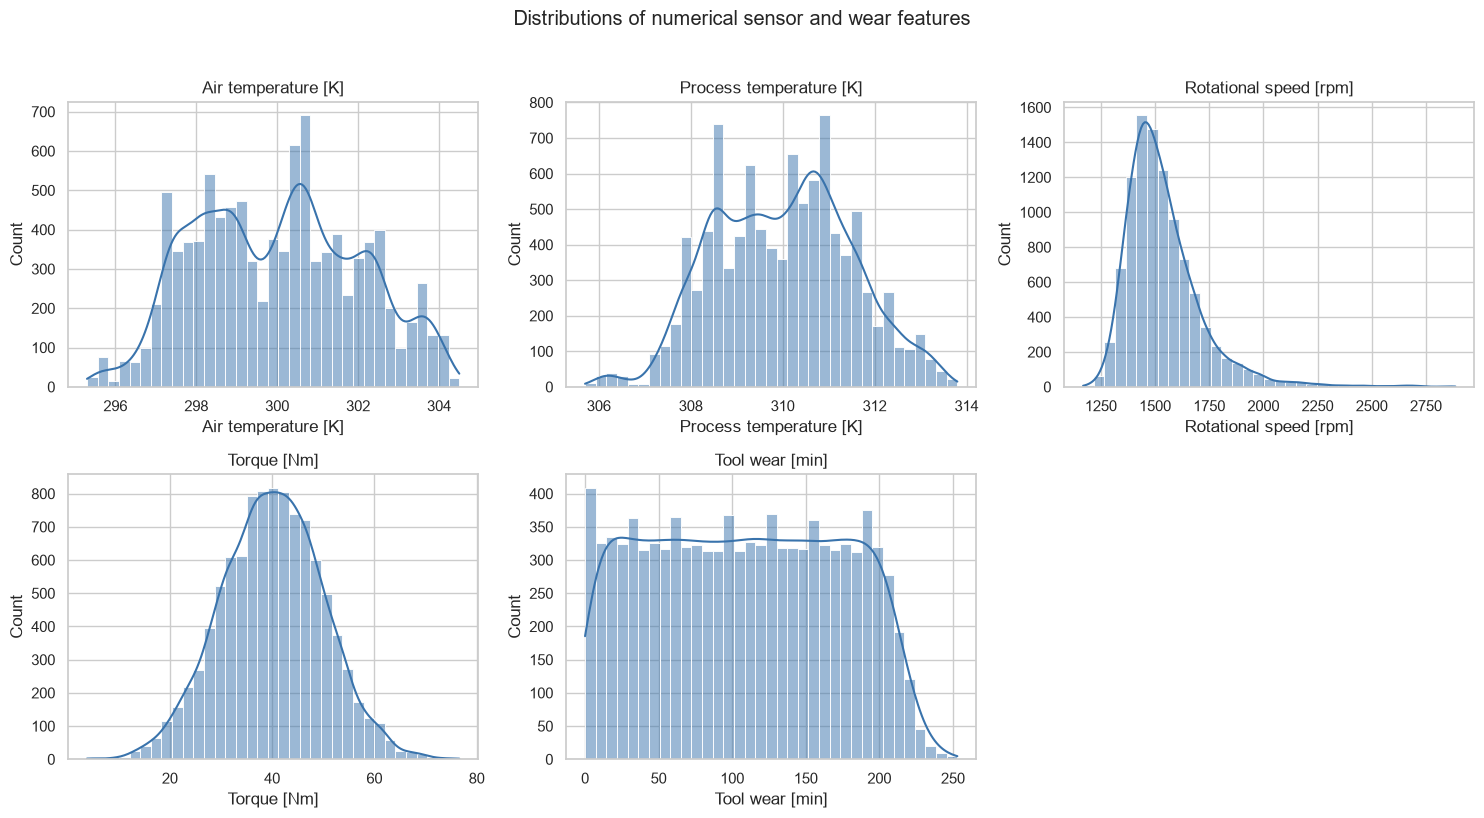

,min,median,mean,max,std
Air temperature [K],295.3,300.1,300.00,304.5,2.00
Process temperature [K],305.7,310.1,310.01,313.8,1.48
Rotational speed [rpm],1168.0,1503.0,1538.78,2886.0,179.28
Torque [Nm],3.8,40.1,39.99,76.6,9.97
Tool wear [min],0.0,108.0,107.95,253.0,63.65


In [5]:
NUMERIC_FEATURES = [
    "Air temperature [K]", "Process temperature [K]",
    "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]",
]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for feature, ax in zip(NUMERIC_FEATURES, axes.flat):
    sns.histplot(data=df, x=feature, bins=35, kde=True, ax=ax, color="#3973ac")
    ax.set_title(feature)
axes.flat[-1].axis("off")
fig.suptitle("Distributions of numerical sensor and wear features", y=1.02)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "numerical_feature_distributions.png", dpi=160, bbox_inches="tight")
plt.show()

display(df[NUMERIC_FEATURES].agg(["min", "median", "mean", "max", "std"]).T.round(2))

**Interpretation.** Compare the histogram shapes and the printed summary statistics to identify skew or unusual ranges. In particular, overlapping temperature distributions and any tail in rotational speed, torque, or tool wear should be considered when selecting preprocessing and models; do not remove observations without a documented data-quality reason.

## Correlations among eligible numeric features

The target is shown only as an exploratory association. The failure-mode columns and identifiers are not included. Correlation is descriptive and does not establish a causal relationship.

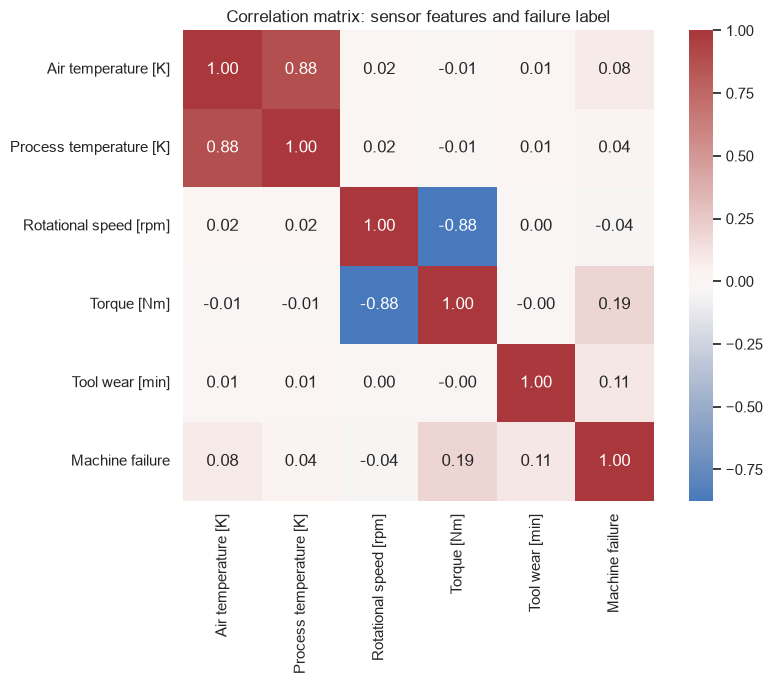

,correlation_with_failure
Torque [Nm],0.191321
Tool wear [min],0.105448
Air temperature [K],0.082556
Rotational speed [rpm],-0.044188
Process temperature [K],0.035946


In [6]:
correlation_columns = NUMERIC_FEATURES + [TARGET]
correlation = df[correlation_columns].corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="vlag", center=0, square=True, ax=ax)
ax.set_title("Correlation matrix: sensor features and failure label")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "feature_target_correlations.png", dpi=160, bbox_inches="tight")
plt.show()
display(correlation[TARGET].drop(TARGET).sort_values(key=lambda values: values.abs(), ascending=False).to_frame("correlation_with_failure"))

**Interpretation.** Read the printed target correlations alongside the heatmap: the largest magnitudes are simple linear associations in this synthetic sample, not causal effects or proof that a feature will generalize to real machinery. Correlations can also miss nonlinear or interaction effects.

## Failure rates across machine types and sensor ranges

Rates are computed from the observed data. Counts are shown with rates so small groups are not interpreted without their sample size.

,records,failures,failure_rate_percent
Type,,,
H,1003,21,2.09
L,6000,235,3.92
M,2997,83,2.77


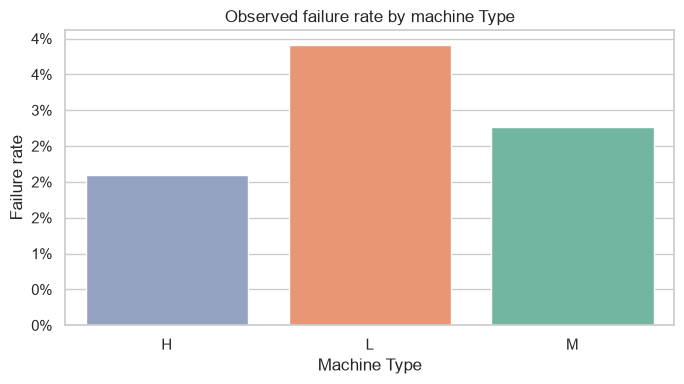

Highest observed Type rate: L (3.92%)


In [7]:
type_summary = df.groupby("Type", observed=True)[TARGET].agg(records="size", failures="sum", failure_rate="mean")
type_summary["failure_rate_percent"] = type_summary["failure_rate"] * 100
display(type_summary.drop(columns="failure_rate").round(2))

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=df, x="Type", y=TARGET, hue="Type", legend=False, errorbar=None, order=sorted(df["Type"].dropna().unique()), ax=ax, palette="Set2")
ax.set(title="Observed failure rate by machine Type", xlabel="Machine Type", ylabel="Failure rate")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
fig.tight_layout()
fig.savefig(FIGURE_DIR / "failure_rate_by_type.png", dpi=160, bbox_inches="tight")
plt.show()
print("Highest observed Type rate:", type_summary["failure_rate"].idxmax(), f"({type_summary['failure_rate'].max():.2%})")

**Interpretation.** Compare the actual per-type rates and counts above. Any visible difference is an association in this synthetic dataset and may reflect how the data was generated; it should not be treated as an operational causal claim.

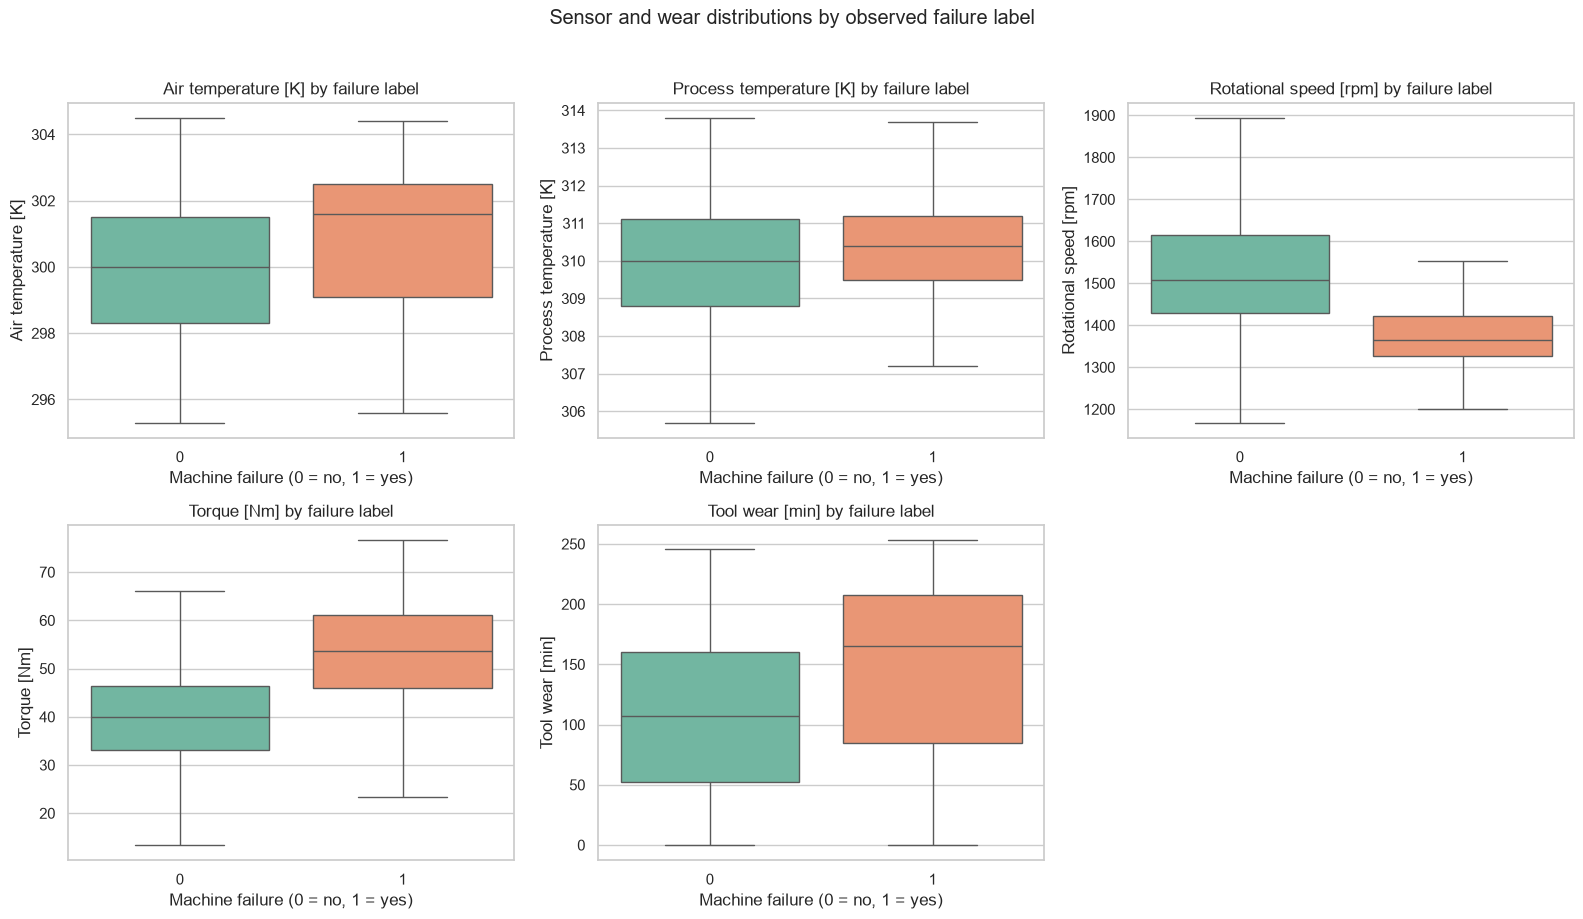

,no_failure_mean,failure_mean,difference_failure_minus_no_failure
Air temperature [K],299.97,300.89,0.91
Process temperature [K],310.00,310.29,0.29
Rotational speed [rpm],1540.26,1496.49,-43.77
Torque [Nm],39.63,50.17,10.54
Tool wear [min],106.69,143.78,37.09


In [8]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for feature, ax in zip(NUMERIC_FEATURES, axes.flat):
    sns.boxplot(data=df, x=TARGET, y=feature, hue=TARGET, legend=False, showfliers=False, ax=ax, palette="Set2")
    ax.set_title(f"{feature} by failure label")
    ax.set_xlabel("Machine failure (0 = no, 1 = yes)")
axes.flat[-1].axis("off")
fig.suptitle("Sensor and wear distributions by observed failure label", y=1.02)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "features_by_failure.png", dpi=160, bbox_inches="tight")
plt.show()

group_means = df.groupby(TARGET)[NUMERIC_FEATURES].mean().T
group_means.columns = ["no_failure_mean", "failure_mean"]
group_means["difference_failure_minus_no_failure"] = group_means["failure_mean"] - group_means["no_failure_mean"]
display(group_means.round(2))

**Interpretation.** Use the box plots and group-mean table to see how sensor ranges differ by label, while keeping in mind that only a small fraction of rows are failures. Overlap is expected and means no single measurement cleanly separates the labels. These marginal views do not account for interactions and do not imply causation.

In [ ]:
binned_rows = []
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for feature, ax in zip(NUMERIC_FEATURES, axes.flat):
    bin_ids = pd.qcut(df[feature], q=5, labels=False, duplicates="drop")
    summary = (
        df.assign(quantile_bin=bin_ids)
        .groupby("quantile_bin", observed=True)[TARGET]
        .agg(records="size", failures="sum", failure_rate="mean")
        .reset_index()
    )
    summary["feature"] = feature
    summary["failure_rate_percent"] = summary["failure_rate"] * 100
    binned_rows.append(summary)
    sns.lineplot(data=summary, x="quantile_bin", y="failure_rate", marker="o", ax=ax, color="#3973ac")
    ax.set(title=feature, xlabel="Quantile bin (low to high)", ylabel="Observed failure rate")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
axes.flat[-1].axis("off")
fig.suptitle("Observed failure rate across sensor-feature quantile bins", y=1.02)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "failure_rate_by_binned_features.png", dpi=160, bbox_inches="tight")
plt.show()
binned_failure_rates = pd.concat(binned_rows, ignore_index=True)
display(binned_failure_rates[["feature", "quantile_bin", "records", "failures", "failure_rate_percent"]].round(2))

**Interpretation.** The line chart and accompanying bin counts show observed failure prevalence across quantile ranges for each measurement. Each quantile bin contains approximately similar numbers of records, though ties can merge bins. Small changes in failure rate can be noisy because failures are rare. These unadjusted, synthetic-data associations do not demonstrate causal effects or operational thresholds.

## EDA checkpoint

Before training, confirm the observed data-quality results above, preserve the listed leakage exclusions, and use stratified splits. All plots created in this notebook are exploratory; no model has been fitted and no held-out test results are reported.